# Question and why it matters
Does RLRLLL share a measurable escape structure with census survivors? See README.md and ../../notes/open-questions-hypotheses.md. # Assumptions and definitions
Blank starts are deterministic (no random seed). Census extents cover whole history; G1 extents cover new cells per window. Only completed chunks enter cohorts. Windows are correlated. # Provenance, data and method
The JSON records every input SHA-256, base commit, recipe and producing script hash. No heavy simulation runs here.

In [1]:
from pathlib import Path
import json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Cargo.toml').exists())
p = root / 'experiments/archive/2026-10-g1-ribbon-breakout/results/survivor_comparison.json'
d = json.loads(p.read_text())
print('Base commit:', d['base_commit'], 'Registration:', d['registration'], 'Seed:', d['seed'])
for path, digest in d['input_sha256'].items():
    print(path, digest)
print('Trace:', d['trace'])
print('Census:', d['census'])
print('Transfer passed:', d['transfer_prediction_pass'])

Base commit: da88e61b690507526ba4e2a2c017d9c7941beb91 Registration: 2026-10-15 21:22 NZDT Seed: None
examples/escape_trace.rs 7c85a15314aa1228c606fd998f9ab939b1fe0e0ec44ae8d03b41c5abad10680e
examples/ribbon_trace.rs a6049fe01781bbe56f9b28562d8bfabbd4c6e8896e2e06ecc0825bb4cea1c6a5
experiments/2026-10-13-c2-arrow-bias/results/escape_trace.txt 1b14dc2602ec6f62d5051affe97de14b6d4c0abfb94082a3471c902109f64de7
experiments/2026-10-13-g1-ribbon-breakout/results/g1_ribbon.csv b0ffc88b3d027ae9062d2d9ab672f39d1eef1ad00d8c31c0f2bc6154d95127e4
experiments/2026-10-13-highways-unresolved-rules-1e10-1e11/results/h1e10/chunk_00.csv 061366980695c1cf3be64d5de829985a82e647c084e020812fd9055fa6cfc1a8
experiments/2026-10-13-highways-unresolved-rules-1e10-1e11/results/h1e10/chunk_00.done e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
experiments/2026-10-13-highways-unresolved-rules-1e10-1e11/results/h1e10/chunk_01.csv 41a1d4494c17ae5008d4af7fcb8f5d4b83541f91eedc3ab4f1e7f6ab09d6702a
experimen

# Results
S passes in 281/298 complete breakout windows and 0/676 preceding windows. This distinguishes the already known phases; it does not establish a mechanism. Zero of 37 earlier and 3 later no-highway escapes satisfy global aspect >=2. This fails T; it does not test their local ribbon geometry. # Caveats and controls
Synthetic efficient slab passes, square and slow slab fail. Historical <=12-cell prediction fails (0/298). Thresholds use historical knowledge. Partial final window excluded; no window-based uncertainty. Later census only 324 completed rules, RLRLLL later row absent. Square-board censoring limits global geometry. # What this changes / next steps
A reproducible local signature exists for RLRLLL. Shared local anatomy remains open. Record local windows for all three later escapes with larger-board and recognised-highway controls; apply S unchanged and test moving-frame recurrence.

## Archival figure: question and assumptions (2026-10-16)
Can one figure show the late efficiency switch, the period-3 wake and the
quantitative sweep check? This is a presentation of existing measurements,
not a new experiment. See README.md and ../../notes/g1-builder-structure-2026-10-14.md.
One deterministic blank-board RLRLLL trajectory; no random seed, no independent
replication. Wake snapshots are taken after each 400,000-step dump.


In [2]:
from pathlib import Path
import hashlib, json, subprocess
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Cargo.toml').is_file())
G1 = ROOT / 'experiments/archive/2026-10-g1-ribbon-breakout/results'
names = ['g1_ribbon.csv', 'g1_wake_extract.json', 'g1_wake_crop_12800000000.csv', 'g1_sweep_trace_12800000000.csv']
print('commit:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip())
print('section date: 2026-10-16 NZDT; seed: none (deterministic blank board)')
for name in names:
    print(name, hashlib.sha256((G1 / name).read_bytes()).hexdigest())
ext = json.loads((G1 / 'g1_wake_extract.json').read_text())['dumps']


commit: c6b5053ce923372fd2facff75966230694990c7b
section date: 2026-10-16 NZDT; seed: none (deterministic blank board)
g1_ribbon.csv b0ffc88b3d027ae9062d2d9ab672f39d1eef1ad00d8c31c0f2bc6154d95127e4
g1_wake_extract.json c91e60f3327a934221bbac1109796531b0bb58862471c04f5c248bc5ff9aea86
g1_wake_crop_12800000000.csv 09d3c453fb822c238562f939b2cf526b9a50092f81f67335c197d3c32071ff20
g1_sweep_trace_12800000000.csv 9d8b22b888856ea2130bcb7d53ce6fc39315dfe92ba2bfdd596c449f4507fde2


### Data, method and results
Original simulation: recovered `examples/g1_ribbon_breakout_builder_dump.rs`.
`scripts/g1_wake_extract.py` makes these compact results; the notebook reads
only committed results. The original post-hoc check fits |x| in a strict
±20,000,000-step window around each dump, then multiplies by 2|x(t0)|.
The model uses 3 columns per 12L steps, hence d|x|²/dt = |x|/(2L).


shape: (2, 5)
┌─────────────┬──────┬───────────┬──────────┬─────────┐
│ t0          ┆ L    ┆ predicted ┆ measured ┆ windows │
│ ---         ┆ ---  ┆ ---       ┆ ---      ┆ ---     │
│ i64         ┆ i64  ┆ f64       ┆ f64      ┆ i64     │
╞═════════════╪══════╪═══════════╪══════════╪═════════╡
│ 12800000000 ┆ 6400 ┆ 0.864883  ┆ 0.862245 ┆ 39      │
│ 12900000000 ┆ 8610 ┆ 0.835453  ┆ 0.832701 ┆ 39      │
└─────────────┴──────┴───────────┴──────────┴─────────┘


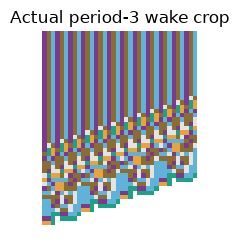

In [3]:
d = pl.read_csv(G1 / 'g1_ribbon.csv').filter(pl.col('t_end') > 12_000_000_000)
rows = []
for t0 in (12_800_000_000, 12_900_000_000):
    e = ext[str(t0)]
    w = d.filter((pl.col('t_end') - t0).abs() < 20_000_000)
    t, x = w['t_end'].to_numpy(), np.abs(w['x'].to_numpy())
    pred = (abs(e['x_start']) + abs(e['x_end'])) / (4 * e['L_traj'])
    measured = 2 * np.interp(t0, t, x) * np.polyfit(t - t0, x, 1)[0]
    rows.append({'t0': t0, 'L': e['L_traj'], 'predicted': pred, 'measured': measured, 'windows': w.height})
print(pl.DataFrame(rows))
e = ext['12800000000']
crop = pl.read_csv(G1 / 'g1_wake_crop_12800000000.csv')['colour'].to_numpy().reshape(80, 36)[:48]
from matplotlib.colors import ListedColormap
palette = ['#e3e3e3', '#1fa187', '#e8a33d', '#7a3b8f', '#5fb3d9', '#8c6d31', '#ffffff']
fig, ax = plt.subplots(figsize=(2, 2.8))
ax.imshow(np.where(crop == 255, 6, crop), cmap=ListedColormap(palette), vmin=0, vmax=6, origin='lower', interpolation='nearest')
ax.set_title('Actual period-3 wake crop'); ax.set_axis_off(); plt.show()


### Caveats, controls and next steps
The wake has a strong three-column repeat, and the two local rates agree
with the sweep picture. These observations do not explain period 3 or the
trigger. The two heights and positions come from one trajectory; this is not
an independent test of L proportional to |x|, and no between-seed error bar
is available. Exporter trajectories and all wake bytes were checked against
an independent obvious ant loop for all 28 rule strings of lengths 2–4;
the Rust release suite is a separate simulator check. No estimator changed,
so no new rotor calibration is implied. See results/builder_oracle_check.log.
Next: obtain a third sweep-height sample and investigate the switching trigger.
